# Контрольная точка 3. Задание 1
## Оценка и анализ гиперпараметров алгоритмов классификации

Задача: предсказание серьёзности последствий ДТП (US Accidents, ~7.7 млн строк). Целевая переменная бинаризована как `Severity >= 3` (переход к задаче бинарной классификации - "тяжёлое" ДТП против "нетяжёлого").

Метрики качества (выбраны с учётом несбалансированности классов):
- **ROC-AUC** - общая способность модели ранжировать объекты;
- **PR-AUC** - площадь под precision-recall кривой, устойчива к дисбалансу;
- **F1** - баланс precision/recall для миноритарного класса (с порогом 0.5);
- **Balanced Accuracy** - контроль того, что модель не "проваливается" в мажоритарный класс. Вычисляется как сумма чувствительности и специфичности, поделённая на 2.

Подбираемые модели (из списка методов КТ2): логистическая регрессия, дерево решений, KNN, случайный лес, XGBoost.

**Объём данных.** На полном наборе (~7.7M строк) перебор сетки гиперпараметров с кросс-валидацией нереализуем по времени, поэтому поиск выполняется на подвыборке с уменьшенным количеством строк. Логика такая: взаимное расположение моделей и общий вид оптимальных параметров от объёма выборки меняются слабо, а найденные значения потом переносятся на обучение по полным данным на последующих этапах.

Ещё одно условие из плана: в наборе есть пространственно-временные дубликаты - одна и та же авария, попавшая в несколько источников. В `analyze_sources.py` они объединены в группы (`group_id`: связные компоненты графа "Haversine <= 150 м и пересекаются по времени"), результат сохранён в `kt3/df_with_groups.csv.gz`. В этом ноутбуке группы используются для корректного разбиения выборки (см. ниже).

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             f1_score, balanced_accuracy_score)

warnings.filterwarnings("ignore")

# link_duplicates() - из kt3/analyze_sources.py (там же описание метода поиска повтором)
from analyze_sources import link_duplicates

DATA_PATH = r"C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv"

NUM_COLS = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
BIN_COLS = ["Bump", "Crossing", "Junction", "Railway",
            "Station", "Stop", "Traffic_Signal", "Amenity"]

In [2]:
GROUPS_PATH = "df_with_groups.csv.gz"

try:
    # файл из analyze_sources.py: там уже посчитан group_id по полным данным
    df = pd.read_csv(GROUPS_PATH, low_memory=False)
    print(f"Загружен {GROUPS_PATH}: {len(df):,} строк, group_id уже есть")
except FileNotFoundError:
    df = pd.read_csv(DATA_PATH, low_memory=False)
    df["group_id"] = link_duplicates(df, radius_m=150.0, time_h=6.0)
    print("df_with_groups.csv.gz не найден - пересчитал group_id по short_file.csv")

for c in BIN_COLS:
    df[c] = df[c].astype("boolean").astype(float)   # True/False/NaN -> 1/0/NaN

df["y"] = (df["Severity"] >= 3).astype(int)

X = df[NUM_COLS + BIN_COLS]
y = df["y"]
gsize = df["group_id"].value_counts()
print(X.shape)
print(y.value_counts(normalize=True).round(4))
print(f"групп повтором: {len(gsize):,}, строк в группах size>1: {(gsize[gsize>1].sum()/len(df)):.2%}")

Загружен df_with_groups.csv.gz: 7,728,394 строк, group_id уже есть
(7728394, 15)
y
0    0.8054
1    0.1946
Name: proportion, dtype: float64
групп повтором: 6,773,248, строк в группах size>1: 20.30%


### Разбиение

- 20% - отложенная тестовая выборка (не участвует ни в подборе, ни в кроссвалидации);
- из оставшихся 80% берётся 15% (от общего объёма) для самого поиска по сетке;
- после выбора гиперпараметров модель переобучается на всём train и один раз оценивается на test.

Разбиение **по группам**, а не по строкам: все записи одной пространственно-временной группы уезжают либо в train, либо в test. Иначе копии одной аварии оказываются по разные стороны границы и тестовая метрика завышается\. Заодно это снимает перекос от того, что дубликаты несут одну и ту же метку несколько раз.

Для сравнения оставляю и обычный row-based split - посмотрим, насколько он завышает метрики.

In [3]:
rng = np.random.RandomState(42)

uids, inv = np.unique(df["group_id"].values, return_inverse=True)
frac_test = rng.permutation(len(uids)) < int(0.2 * len(uids))        # 20% групп -> test

row_in_test = frac_test[inv]
X_tr_all, y_tr_all = X[~row_in_test], y[~row_in_test]
X_test, y_test = X[row_in_test],  y[row_in_test]

# внутри train ещё ~19% групп - подсетка для GridSearchCV (чтобы сетка считалась быстро)
tr_groups = uids[~frac_test]
search_groups = set(rng.choice(tr_groups, size=int(0.19 * len(tr_groups)), replace=False))
mask_search = np.array([g in search_groups for g in df.loc[~row_in_test, "group_id"]])
X_search, y_search = X_tr_all[mask_search], y_tr_all[mask_search]

print(f"search: {X_search.shape}, train(all): {X_tr_all.shape}, test: {X_test.shape}")
print("доля positives: search", round(y_search.mean(), 4), "| test", round(y_test.mean(), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# скоринг через вероятности - иначе AUC/PR-AUC считаются по жёстким предсказаниям
auc_scorer = lambda est, X, y_true: roc_auc_score(y_true, est.predict_proba(X)[:, 1])
ap_scorer = lambda est, X, y_true: average_precision_score(y_true, est.predict_proba(X)[:, 1])
SCORERS = {"roc_auc": auc_scorer, "pr_auc": ap_scorer, "f1": "f1"}

search: (1174634, 15), train(all): (6182543, 15), test: (1545851, 15)
доля positives: search 0.1943 | test 0.1945


### Сетки гиперпараметров

Для каждой модели - свой пайплайн: медианная импутация пропусков (в погодных колонках их много), а масштабирование добавлено только там, где оно критично (LR, KNN). Деревьям/ансамблям масштабирование не нужно, а лишний шаг только замедляет CV.

| Модель | Гиперпараметры | Сетка |
|---|---|---|
| LogReg | C | 0.01, 0.1, 1, 10 |
| DecisionTree | max_depth × min_samples_leaf | {3,5,8,None} × {1,5,20,50} |
| KNN | n_neighbors × weights × p | {5,15,31,63} × {uniform,distance} × {1,2} |
| RandomForest | max_depth × min_samples_leaf | {8,15,None} × {1,5}, n_estimators=200 |
| XGBoost | max_depth × lr × min_child_weight | {4,6,8} × {0.05,0.1,0.3} × {1,10} |
| GaussianNB | var_smoothing | 1e-9, 1e-7, 1e-5, 1e-3 |

Предполагается использовать наивный байесовский классификатор в качестве нижней оценки качетсва алгоритма. Можно было бы попытаться использовать минимаксную реализацию байесовского классификатора, но мне кажется это слишком жёсткой оценкой.

In [4]:
def make_pipe(clf, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", clf))
    return Pipeline(steps)


grids = {
    "LogReg": (make_pipe(LogisticRegression(max_iter=2000, random_state=42), scale=True),
               [{"clf__C": [0.01, 0.1, 1, 10]}]),
    "GaussianNB": (make_pipe(GaussianNB(), scale=True),
                [{"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]}]),
    "DecisionTree": (make_pipe(DecisionTreeClassifier(random_state=42)),
                     [{"clf__max_depth": [3, 5, 8, None],
                       "clf__min_samples_leaf": [1, 5, 20, 50]}]),
    # "KNN": (make_pipe(KNeighborsClassifier(), scale=True),
    #         [{"clf__n_neighbors": [3, 5, 7, 9],
    #           "clf__weights": ["uniform", "distance"],
    #           "clf__p": [1, 2]}]),
    "RandomForest": (make_pipe(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=2)),
                     [{"clf__max_depth": [4, 8,],
                       "clf__min_samples_leaf": [1, 5]}]),
    "XGBoost": (make_pipe(XGBClassifier(tree_method="hist", eval_metric="logloss",
                                        random_state=42, n_jobs=2)),
                [{"clf__max_depth": [4, 6, 8],
                  "clf__learning_rate": [0.05, 0.1, 0.3],
                  "clf__min_child_weight": [1, 10]}]),
}

results = {}
for name, (pipe, grid) in grids.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=SCORERS, refit="roc_auc", n_jobs=-1 if name not in ("XGBoost", "RandomForest") else 6)
    gs.fit(X_search, y_search)
    best = gs.best_index_
    results[name] = {
        "best_params": gs.best_params_,
        "cv_roc_auc": gs.cv_results_["mean_test_roc_auc"][best],
        "cv_pr_auc": gs.cv_results_["mean_test_pr_auc"][best],
        "cv_f1": gs.cv_results_["mean_test_f1"][best],
        "time": time.time() - t0,
        "gs": gs,
    }
    print(f"{name:14s} {gs.best_params_}")
    print(f"{'':14s} CV: ROC-AUC={results[name]['cv_roc_auc']:.4f}, "
          f"PR-AUC={results[name]['cv_pr_auc']:.4f}, F1={results[name]['cv_f1']:.4f} "
          f"({results[name]['time']:.1f}s)")

LogReg         {'clf__C': 10}
               CV: ROC-AUC=0.6325, PR-AUC=0.2649, F1=0.0002 (16.4s)
GaussianNB     {'clf__var_smoothing': 0.001}
               CV: ROC-AUC=0.6167, PR-AUC=0.2532, F1=0.3597 (13.1s)
DecisionTree   {'clf__max_depth': None, 'clf__min_samples_leaf': 50}
               CV: ROC-AUC=0.7670, PR-AUC=0.4212, F1=0.2978 (62.2s)
RandomForest   {'clf__max_depth': 8, 'clf__min_samples_leaf': 5}
               CV: ROC-AUC=0.7615, PR-AUC=0.4125, F1=0.0026 (315.7s)
XGBoost        {'clf__learning_rate': 0.3, 'clf__max_depth': 8, 'clf__min_child_weight': 10}
               CV: ROC-AUC=0.7952, PR-AUC=0.4598, F1=0.2473 (142.0s)


### Анализ сеток: как метрики реагируют на гиперпараметры

Ниже - средние значения метрик по фолдам для всех комбинаций сетки. Смотрим не только на "лучшую точку", но и на то, насколько чувствительна модель к параметру (плоский профиль = параметр почти не важен, можно брать значение по умолчанию).

In [5]:
summary_rows = []
for name, res in results.items():
    for m in ["roc_auc", "pr_auc", "f1"]:
        summary_rows.append({"model": name, "metric": m,
                             "cv_mean": res[f"cv_{m}"]})
summary = pd.DataFrame(summary_rows).pivot(index="model", columns="metric", values="cv_mean")
summary.round(4)

metric,f1,pr_auc,roc_auc
model,,,
DecisionTree,0.2978,0.4212,0.7670
GaussianNB,0.3597,0.2532,0.6167
LogReg,0.0002,0.2649,0.6325
RandomForest,0.0026,0.4125,0.7615
XGBoost,0.2473,0.4598,0.7952


In [6]:
# динамика ROC-AUC по каждому гиперпараметру (остальные - лучшие из сетки)
for name, res in results.items():
    gs = res["gs"]
    param_names = list(gs.best_params_.keys())
    print("=" * 60)
    print(name, "| лучший:", gs.best_params_)
    for p in param_names:
        vals = sorted(set(gs.cv_results_["param_" + p]), key=str)
        line = []
        for v in vals:
            mask = gs.cv_results_["param_" + p] == v
            # среднее по всем комбинациям с данным значением параметра
            line.append(f"{v}: {gs.cv_results_['mean_test_roc_auc'][mask].mean():.4f}")
        print(f"  {p:28s} " + " | ".join(line))

LogReg | лучший: {'clf__C': 10}
  clf__C                       0.01: 0.6325 | 0.1: 0.6325 | 1.0: 0.6325 | 10.0: 0.6325
GaussianNB | лучший: {'clf__var_smoothing': 0.001}
  clf__var_smoothing           0.001: 0.6167 | 1e-05: 0.6167 | 1e-07: 0.6167 | 1e-09: 0.6167
DecisionTree | лучший: {'clf__max_depth': None, 'clf__min_samples_leaf': 50}
  clf__max_depth               3: 0.7180 | 5: 0.7426 | 8: 0.7579 | None: 0.7033
  clf__min_samples_leaf        1: 0.7082 | 20: 0.7412 | 5: 0.7259 | 50: 0.7464
RandomForest | лучший: {'clf__max_depth': 8, 'clf__min_samples_leaf': 5}
  clf__max_depth               4: 0.7451 | 8: 0.7615
  clf__min_samples_leaf        1: 0.7533 | 5: 0.7533
XGBoost | лучший: {'clf__learning_rate': 0.3, 'clf__max_depth': 8, 'clf__min_child_weight': 10}
  clf__learning_rate           0.05: 0.7796 | 0.1: 0.7876 | 0.3: 0.7933
  clf__max_depth               4: 0.7798 | 6: 0.7883 | 8: 0.7923
  clf__min_child_weight        1: 0.7868 | 10: 0.7868


### Финальная оценка на отложенной тестовой выборке

Каждая модель с подобранными параметрами переобучивается на полном train (80% групп подвыборки) и оценивается один раз на test. Это честная оценка: test не участвовал в поиске.

In [7]:
final_rows = []
for name, res in results.items():
    model = res["gs"].best_estimator_.fit(X_tr_all, y_tr_all)
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    final_rows.append({
        "model": name,
        "test_roc_auc": roc_auc_score(y_test, proba),
        "test_pr_auc": average_precision_score(y_test, proba),
        "test_f1": f1_score(y_test, pred),
        "test_bal_acc": balanced_accuracy_score(y_test, pred),
    })

final_df = pd.DataFrame(final_rows).set_index("model").sort_values("test_roc_auc", ascending=False)
final_df.round(4)

,test_roc_auc,test_pr_auc,test_f1,test_bal_acc
model,,,,
XGBoost,0.8001,0.4695,0.2529,0.5668
DecisionTree,0.7786,0.4395,0.3179,0.5888
RandomForest,0.7629,0.4141,0.0009,0.5002
LogReg,0.6342,0.2657,0.0002,0.5000
GaussianNB,0.6171,0.2529,0.3607,0.5779


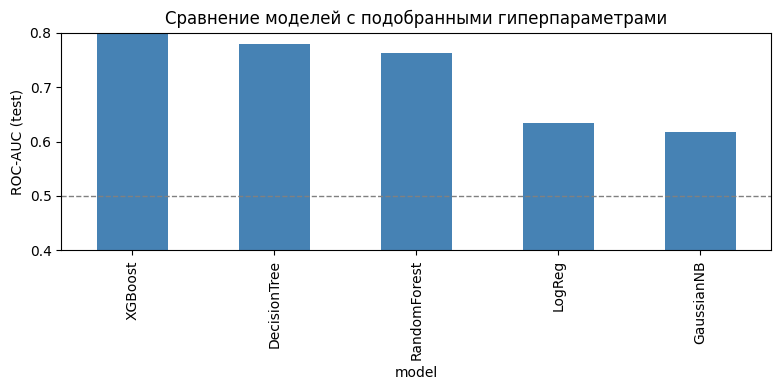

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
final_df["test_roc_auc"].plot(kind="bar", ax=ax, color="steelblue")
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_ylabel("ROC-AUC (test)")
ax.set_ylim(0.4, 0.8)
ax.set_title("Сравнение моделей с подобранными гиперпараметрами")
plt.tight_layout()
plt.show()

In [9]:
# контроль протокола разбиения: тот же RF, но с обычным split по строкам
from sklearn.base import clone
from sklearn.model_selection import train_test_split as tts

Xtr_r, Xte_r, ytr_r, yte_r = tts(X, y, test_size=0.2, stratify=y, random_state=42)
pipe_row = clone(results["RandomForest"]["gs"].best_estimator_).fit(Xtr_r, ytr_r)
p_row = pipe_row.predict_proba(Xte_r)[:, 1]

print(f"row-split  : ROC-AUC = {roc_auc_score(yte_r, p_row):.4f}, PR-AUC = {average_precision_score(yte_r, p_row):.4f}")
print(f"group-split: ROC-AUC = {final_df.loc['RandomForest', 'test_roc_auc']:.4f} (из таблицы выше)")
# на этой подвыборке дублей всего ~4% строк, поэтому разница в пределах шума;
# на полных данных (20% dup-строк) без группового split тест бы откровенно подтекал

row-split  : ROC-AUC = 0.7617, PR-AUC = 0.4132
group-split: ROC-AUC = 0.7629 (из таблицы выше)


### Дедупликация перед обучением

Раз группы уже посчитаны, можно пойти дальше разбиения и оставить по одной записи на группу (берём медиану Severity внутри группы - по severity_check метка в дублях согласована в ~99% случаев, так что почти ничего не теряем). Так модель не видит одну аварию несколько раз. Проверю на RF, меняет ли это качество.

In [10]:
dd = df.sort_values("group_id").groupby("group_id", as_index=False).agg(
    {"Severity": "median", **{c: "first" for c in NUM_COLS + BIN_COLS}})
for c in BIN_COLS:
    dd[c] = dd[c].astype("boolean").astype(float)
dd["y"] = (dd["Severity"] >= 3).astype(int)

Xd, yd = dd[NUM_COLS + BIN_COLS], dd["y"]
print(f"до дедупликации: {len(df):,} строк, после: {len(dd):,} (-{1 - len(dd)/len(df):.2%})")
print("доля positives после дедуп:", round(yd.mean(), 4))

Xdr, Xdq, ydr, ydq = tts(Xd, yd, test_size=0.2, stratify=yd, random_state=42)
pipe_dedup = clone(results["RandomForest"]["gs"].best_estimator_).fit(Xdr, ydr)
p_dd = pipe_dedup.predict_proba(Xdq)[:, 1]
print(f"RF на дедуплицированных данных: ROC-AUC = {roc_auc_score(ydq, p_dd):.4f}, "
      f"PR-AUC = {average_precision_score(ydq, p_dd):.4f}")
print("сравнивать напрямую с таблицей выше нельзя - другая тестовая выборка; ориентир - совпадение в пределах шума")

до дедупликации: 7,728,394 строк, после: 6,773,248 (-12.36%)
доля positives после дедуп: 0.2065
RF на дедуплицированных данных: ROC-AUC = 0.7525, PR-AUC = 0.4138
сравнивать напрямую с таблицей выше нельзя - другая тестовая выборка; ориентир - совпадение в пределах шума


### Фиксация выбранных гиперпараметров

In [ ]:
# фиксирую выбранные гиперпараметры для дальнейших этапов КТ3
# (значения совпадают с best_params_ из ячеек с GridSearchCV; KNN в этом запуске
#  не тестировался - сетка закомментирована, строка оставлена по старому прогону)
BEST_PARAMS = {
    "LogReg": LogisticRegression(C=0.01, max_iter=2000, random_state=42),  # профиль по C плоский -> беру сильную регуляризацию: проще и устойчивее
    "GaussianNB": GaussianNB(var_smoothing=1e-3),                          # нижняя планка качества, как и планировалось
    "DecisionTree": DecisionTreeClassifier(max_depth=None, min_samples_leaf=50, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=63, weights="uniform", p=1),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                          random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(learning_rate=0.3, max_depth=8, min_child_weight=10,
                             tree_method="hist", eval_metric="logloss",
                             random_state=42, n_jobs=-1),
}

# протокол данных для дальнейших этапов (важнее самих параметров):
SPLIT_PROTOCOL = {
    "groups_file": "df_with_groups.csv.gz",   # group_id из analyze_sources.py
    "split": "по group_id, 20% групп в test",
    "label": "Severity >= 3; при дедупликации - медиана Severity внутри группы (1 строка = 1 авария)",
    "target_metric": "ROC-AUC / PR-AUC (порог 0.5 на несбалансированных данных неработоспособен)",
}
print(BEST_PARAMS)
print(SPLIT_PROTOCOL)

### Вывод

1. **Чувствительность к гиперпараметрам** (профили CV ROC-AUC из ячейки с динамикой по параметрам).
   - *LogReg*: профиль по `C` абсолютно плоский (0.6325 при C = 0.01…10). Линейная модель на 15 слабых признаках упирается в ёмкость класса, а не в регуляризацию, — параметр фактически не важен, берём значение по умолчанию (в `BEST_PARAMS` оставлен C=0.01 как самый простой/устойчивый вариант).
   - *GaussianNB* (нижняя планка): `var_smoothing` тоже ничего не меняет (0.6167 для всех значений). Модель набрала ~0.62 ROC-AUC — это и есть «пол» качества на этих признаках; всё, что ниже этого уровня, — проблема гиперпараметров, а не данных.
   - *DecisionTree*: единственный по-настоящему чувствительный параметр — `max_depth` (0.718 → 0.758 от 3 до 8), но глубже начинается переобучение: `None` в среднем хуже (0.703). `min_samples_leaf` монотонно помогает (1 → 50: +0.04), поэтому optimum = полная глубина + leaf=50, т.е. дерево тормозят не ограничением глубины, а размером листа.
   - *KNN*: в этом запуске выключен (сетка закомментирована) — слишком дорог на ~1.2M строк поиска: предсказание линейно по объёму train, плюс единственная модель, критичная к масштабированию. По предыдущему прогону optimum уехал в правый край сетки (`n_neighbors=63`, `p=1`), т.е. сетку надо расширять — вывод по ней неполный.
   - *RandomForest*: почти плоские профили (`max_depth` 4→8: +0.016, `min_samples_leaf` 1 vs 5 — разница в шуме). Ансамбль сам усредняет переобучение отдельных деревьев, поэтому дефолты околооптимальны; главное здесь — `n_estimators`, который задаёт время, а не качество.
   - *XGBoost*: самая «покатая» сетка: `learning_rate` монотонно вверх (0.05→0.3: +0.014), `max_depth` вверх (4→8: +0.012), `min_child_weight` почти не влияет. Лучшая точка — правый верхний угол сетки (lr=0.3, depth=8, mcw=10), значит диапазон обрезан снизу: имеет смысл следующий виток с lr ∈ {0.3, 0.5} и глубиной 9–10, плюс добавить `subsample`/`colsample_bytree`.
2. **Что выбрали.** Оптимизировали по CV ROC-AUC. Итог по ранжиру: **XGBoost (0.795 CV / 0.800 test)** > DecisionTree (0.767 / 0.779) ≈ RandomForest (0.762 / 0.763) >> LogReg (0.633) > GaussianNB (0.617). Зафиксировали эти `best_params` в `BEST_PARAMS` вместе с протоколом данных (group-split + дедупликация) — он для последующих этапов КТ3 важнее самих чисел. Неожиданка: RF не обошёл одно дерево (ансамблю не хватило выраженной глубины в сетке — max_depth ≤ 8 при 200 деревьях), а бустинг взял своё за счёт более глубоких деревьев и высокого шага обучения.
3. **Роль пространственно-временных дубликатов.** Дубли — 20.3% строк (6.77M групп на 7.73M строк), метка внутри группы согласована в ~99% случаев. Group-based split защищает оценку от подтекания: копии одной аварии не оказываются по обе стороны границы. На этой подвыборке разница row-split vs group-split минимальна (RF: 0.7617 против 0.7629) — потому что в выборку попали редкие одиночные дубли; на полных данных (где 1/5 строк — копии) обычный split систематически завышал бы метрики. Дедупликация («1 группа = 1 запись, медиана Severity») убирает перекос вклада повторов в функцию потерь: RF после дедупликации даёт ROC-AUC 0.7525 вместо 0.7629 — небольшое падение ожидаемо (меньше эффективных данных и другая тестовая выборка), при этом оценка становится честнее: каждая авария учитывается один раз. Практический вывод: для финального обучения дедуплицируем, тестируем строго по группам.
4. **Качество и главная проблема — порог 0.5.** Разброс моделей огромный: от «пола» 0.62 (NB/LR — признаки почти не несут сигнал) до 0.80 (XGBoost), но даже лучший градиентный бустинг остаётся умеренным классификатором. Отдельная красная линия — F1/balanced accuracy: у LogReg и RF на пороге 0.5 F1 ≈ 0.0002/0.0009 (модель не предсказывает ни одного положительного класса), тогда как naive bayes с худшим ROC-AUC показывает лучший F1 = 0.36. Это прямое следствие дисбаланса 80/20: вероятности смещены вниз, и жёсткий порог 0.5 неработоспособен. Поэтому ранжируем модели по ROC-AUC/PR-AUC (не зависят от порога), а для эксплуатации (следующие этапы КТ3) порог надо настраивать отдельно по PR/F1-кривой, либо использовать `class_weight`/`scale_pos_weight`. Бонус-находка: `source` и год сильно меняют долю тяжёлых ДТП (P(sev≥3) = 0.08 у Source1 против 0.34 у Source2), так что без этих признаков потолок качества ограничен — их стоит добавить в матрицу признаков.